<a href="https://colab.research.google.com/github/CeZa18/ITAI_1372_Labs/blob/main/llm_phishing_analysis_lab_v2_CesarZaldivar_ITAI1372.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Phishing Email Analysis using LLMs

## Introduction

This Jupyter notebook demonstrates how to use Large Language Models (LLMs) to analyze emails for potential phishing attempts. We'll use the Ollama framework to run a local LLM, then create a simple GUI for one-shot email analysis. Finally, we will test our process with a realworld datasets of phishing emails.

## Setup

First, we need to install Ollama and set up our environment. The setup is exactly the same that we did in the the previous collab.

In [4]:
!curl https://ollama.ai/install.sh | sh

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
  0     0    0     0    0     0      0      0 --:--:-- --:--:-- --:--:--     0


In [8]:
# Check if Colab can connect to ollama.com
!curl -I -L --connect-timeout 15 --max-time 30 https://ollama.com

HTTP/2 200 
content-type: text/html; charset=utf-8
set-cookie: aid=6b69bda6-0c1e-4f36-b3eb-a72004e1a0b0; Path=/; Max-Age=31536000; HttpOnly; Secure; SameSite=Lax
x-build-commit: 2b5a7b084e4832c048267d9a55fcf02fe8f80a0f
x-build-time: 2026-10-30T19:32:18-07:00
x-frame-options: DENY
x-request-id: 5c5426c1-71d7-4b69-b4f9-d91c3f012032
date: Sat, 31 Oct 2026 20:09:00 GMT
server: Google Frontend
traceparent: 00-fe3ae150a53d3d2d597455e191098e7f-79e6db7bfeaff6f3-00
x-cloud-trace-context: fe3ae150a53d3d2d597455e191098e7f/8783949448833136371
via: 1.1 google
alt-svc: h3=":443"; ma=2592000



In [7]:
# Install zstf to unzip and isntall Ollama
!sudo apt-get update && sudo apt-get install -y zstd

Get:1 https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2404/x86_64  InRelease [1,578 B]
Get:2 https://cli.github.com/packages stable InRelease [3,917 B]
Get:3 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ InRelease [3,631 B]
Hit:4 http://archive.ubuntu.com/ubuntu noble InRelease
Get:5 https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2404/x86_64  Packages [2,000 kB]
Get:6 https://cli.github.com/packages stable/main amd64 Packages [357 B]
Get:7 http://archive.ubuntu.com/ubuntu noble-updates InRelease [126 kB]
Get:8 http://security.ubuntu.com/ubuntu noble-security InRelease [126 kB]
Get:9 https://r2u.stat.illinois.edu/ubuntu noble InRelease [9,161 B]
Get:10 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ Packages [75.7 kB]
Get:11 http://archive.ubuntu.com/ubuntu noble-backports InRelease [126 kB]
Get:12 https://r2u.stat.illinois.edu/ubuntu noble/main amd64 Packages [3,108 kB]
Get:13 http://archive.ubuntu.com/ubuntu noble-updates/restrict

In [9]:
!curl -fsSL https://ollama.com/install.sh | sh

>>> Cleaning up old version at /usr/local/lib/ollama
>>> Installing ollama to /usr/local
>>> Downloading ollama-linux-amd64.tar.zst
######################################################################## 100.0%
>>> Creating ollama user...
>>> Adding ollama user to video group...
>>> Adding current user to ollama group...
>>> Creating ollama systemd service...
>>> The Ollama API is now available at 127.0.0.1:11434.
>>> Install complete. Run "ollama" from the command line.


In [1]:
# Check Ollama installation is complete
!command -v ollama || echo "Ollama is not in PATH"
!which ollama || true
!ollama --version

/usr/local/bin/ollama
/usr/local/bin/ollama


In [3]:
# Start Ollama manually since systemd could not be install in Colab.
!nohup ollama serve > /tmp/ollama.log 2>&1 &
!sleep 5
!cat /tmp/ollama.log

time=2026-10-31T20:44:06.269Z level=INFO source=routes.go:2474 msg="server config" env="map[CUDA_VISIBLE_DEVICES: GGML_VK_VISIBLE_DEVICES: GPU_DEVICE_ORDINAL: HIP_VISIBLE_DEVICES: HSA_OVERRIDE_GFX_VERSION: HTTPS_PROXY: HTTP_PROXY: LLAMA_ARG_FIT: LLAMA_ARG_FIT_TARGET: NO_PROXY: OLLAMA_CONTEXT_LENGTH:0 OLLAMA_CREATE_REMOTE:false OLLAMA_DEBUG:INFO OLLAMA_DEBUG_LOG_REQUESTS:false OLLAMA_EDITOR: OLLAMA_FLASH_ATTENTION:false OLLAMA_GO_TEMPLATE:true OLLAMA_GPU_OVERHEAD:0 OLLAMA_HOST:http://127.0.0.1:11434 OLLAMA_IGPU_ENABLE: OLLAMA_KEEP_ALIVE:5m0s OLLAMA_KV_CACHE_TYPE: OLLAMA_LLM_LIBRARY: OLLAMA_LOAD_TIMEOUT:5m0s OLLAMA_MAX_LOADED_MODELS:0 OLLAMA_MAX_QUEUE:512 OLLAMA_MAX_TRANSFER_STREAMS:4 OLLAMA_MODELS:/root/.ollama/models OLLAMA_NOHISTORY:false OLLAMA_NOPRUNE:false OLLAMA_NO_CLOUD:false OLLAMA_NUM_PARALLEL:1 OLLAMA_ORIGINS:[http://localhost https://localhost http://localhost:* https://localhost:* http://127.0.0.1 https://127.0.0.1 http://127.0.0.1:* https://127.0.0.1:* http://0.0.0.0 https:

In [4]:
# Verify whether the server is responding
!curl -sS http://127.0.0.1:11434/api/tags

{"models":[{"name":"llama3.2:1b","model":"llama3.2:1b","modified_at":"2026-10-31T20:34:16.557511087Z","size":1321098329,"digest":"baf6a787fdffd633537aa2eb51cfd54cb93ff08e28040095462bb63daf552878","details":{"parent_model":"","format":"gguf","family":"llama","families":["llama"],"parameter_size":"1.2B","quantization_level":"Q8_0","context_length":131072,"embedding_length":2048,"runner":"ggml"},"capabilities":["completion","tools"]}]}

In [5]:
# Pull the model llama3.2:1b
!ollama pull llama3.2:1b

In [6]:
# Check if ollama is installed
!ollama list

NAME           ID              SIZE      MODIFIED      
llama3.2:1b    baf6a787fdff    1.3 GB    3 seconds ago    


Next, we'll set up the necessary environment variables and start the Ollama server:

In [7]:
import os
import asyncio
import threading
import time

# NB: You may need to set these depending and get cuda working depending which backend you are running.
# Set environment variable for NVIDIA library
# Set environment variables for CUDA
os.environ['PATH'] += ':/usr/local/cuda/bin'
# Set LD_LIBRARY_PATH to include both /usr/lib64-nvidia and CUDA lib directories
os.environ['LD_LIBRARY_PATH'] = '/usr/lib64-nvidia:/usr/local/cuda/lib64'

# Helper functions to run Ollama server
async def run_process(cmd, stdout=None, stderr=None):
    print('>>> starting', *cmd)
    process = await asyncio.create_subprocess_exec(
        *cmd,
        stdout=stdout or asyncio.subprocess.PIPE,
        stderr=stderr or asyncio.subprocess.PIPE
    )

    if stdout is None and stderr is None:
        async def pipe(lines):
            async for line in lines:
                print(line.decode().strip())

        await asyncio.gather(
            pipe(process.stdout),
            pipe(process.stderr),
        )
    else:
        await process.wait()

async def start_ollama_serve():
    await run_process(['ollama', 'serve'],
                      stdout=open(os.devnull, 'w'),
                      stderr=open(os.devnull, 'w'))

# Start Ollama server in a separate thread
def run_async_in_thread(loop, coro):
    asyncio.set_event_loop(loop)
    loop.run_until_complete(coro)
    loop.close()

# Create a new event loop that will run in a new thread
new_loop = asyncio.new_event_loop()

# Start ollama serve in a separate thread so the cell won't block execution
thread = threading.Thread(target=run_async_in_thread, args=(new_loop, start_ollama_serve()))
thread.start()

# Wait 5s for ollama to load
time.sleep(5)

>>> starting ollama serve


## Install dependencies

Now, let's install the required Python packages that we will need.


In [8]:
# We first need to install dependencies
%pip install openai pydantic instructor ipywidgets beautifulsoup4 pandas tqdm chardet matplotlib seaborn wordcloud

## Download the LLM model

You can use another model available in the [ollama library](https://ollama.com/library)

In [9]:
import os

# Set the MODEL variable
OLLAMA_MODEL = "gemma2:9b-instruct-q4_K_M"

# Run the ollama pull command
!ollama pull {OLLAMA_MODEL}

## Define data models

Let's define our Pydantic models for structuring the phishing analysis results:

In [10]:
from pydantic import BaseModel, Field
from enum import Enum
from typing import List

class PhishingProbability(str, Enum):
    LOW = "low"
    MEDIUM = "medium"
    HIGH = "high"

class SuspiciousElement(BaseModel):
    element: str
    reason: str

class SimplePhishingAnalysis(BaseModel):
    is_potential_phishing: bool
    phishing_probability: PhishingProbability
    suspicious_elements: List[SuspiciousElement]
    recommended_actions: List[str]
    explanation: str

## Implement email analysis function

Now, let's create a function to analyze emails using our LLM:

In [11]:
from openai import OpenAI
import instructor


def analyze_email(email_content: str) -> SimplePhishingAnalysis:
    client = instructor.from_openai(
      OpenAI(
          base_url="http://127.0.0.1:11434/v1",
          api_key="ollama",  # required, but unused
      ),
      mode=instructor.Mode.JSON,
  )

    resp = client.chat.completions.create(
        model=OLLAMA_MODEL,
        messages=[
            {
                "role": "system",
                "content": "You are an advanced AI assistant specialized in cybersecurity, particularly in detecting and analyzing phishing attempts in emails. Your task is to analyze the provided email content and metadata to determine if it's a potential phishing attempt. You must provide your analysis in a structured format that matches the model.",
            },
            {
                "role": "user",
                "content": email_content,
            },
        ],
        response_model=SimplePhishingAnalysis,
    )
    return resp

## Test the analysis function

Let's test our analysis function with example emails:

In [12]:
import json

# Example phishing email
phishing_email = """
From: security@amazonsupport.net
To: john.doe@company.com
Subject: Urgent: Your Amazon Account Has Been Locked

Dear Valued Customer,

We have detected unusual activity on your Amazon account. To prevent unauthorized access, we have temporarily locked your account for your protection.

To unlock your account and restore full access, please click on the link below and verify your information:

https://amaz0n-account-verify.com/unlock-account

If you do not verify your account within 24 hours, it will be permanently disabled.

Thank you for your prompt attention to this matter.

Best regards,
Amazon Security Team

This email was sent by Amazon.com. To ensure delivery to your inbox, please add security@amazonsupport.net to your address book.
"""

analysis = analyze_email(phishing_email)
print(json.dumps(analysis.model_dump(), indent=2))

# Example legitimate email
legitimate_email = """
From: jennifer.smith@company.com
To: team@company.com
Subject: Quarterly Review Meeting - Thursday, 2 PM

Dear Team,

I hope this email finds you well. I'm writing to remind everyone about our upcoming Quarterly Review Meeting scheduled for this Thursday at 2 PM in the main conference room.

Agenda:
1. Q2 Performance Overview
2. Project Updates
3. Q3 Goals and Strategies
4. Open Discussion

Please come prepared with your team's updates and any questions you may have. If you're unable to attend in person, you can join via our usual video conferencing link:
https://company.zoom.us/j/123456789

Don't forget to bring your laptops for the interactive portion of the meeting.

If you have any questions or need to discuss anything before the meeting, feel free to drop by my office or send me an email.

Looking forward to seeing everyone on Thursday!

Best regards,
Jennifer Smith
Head of Operations
Company Inc.
"""

analysis = analyze_email(legitimate_email)
print(json.dumps(analysis.model_dump(), indent=2))

{
  "is_potential_phishing": true,
  "phishing_probability": "high",
  "suspicious_elements": [
    {
      "element": "Sender Email Address",
      "reason": "The sender email address (security@amazonsupport.net) is slightly different from the expected Amazon Support address. Phishing emails often use similar-looking addresses to deceive recipients."
    },
    {
      "element": "Urgent Subject Line",
      "reason": "The subject line uses alarming language ('Urgent: Your Amazon Account Has Been Locked') to pressure recipients into taking immediate action without thinking."
    },
    {
      "element": "Suspicious Link",
      "reason": "The provided link (https://amaz0n-account-verify.com/unlock-account) is suspicious and does not appear to be a legitimate Amazon address. It contains a slight misspelling ('amaz0n') which is a common phish technique."
    },
    {
      "element": "Threat of Account Closure",
      "reason": "The email threatens the permanent disabling of the accoun

## Create a GUI for Email Analysis

Finally, let's create a simple GUI for email analysis using IPython widgets. It will take as input only a text box but you can improve it by using a mailbox parser, supporting attachments, ioc extractions...

In [13]:
from IPython.display import display, HTML
import ipywidgets as widgets

# GUI components
email_input = widgets.Textarea(
    value='',
    placeholder='Paste the email content here...',
    description='Email:',
    disabled=False,
    layout={'width': '100%', 'height': '200px'}
)

analyze_button = widgets.Button(
    description='Analyze Email',
    disabled=False,
    button_style='primary',
    tooltip='Click to analyze the email',
    icon='check'
)

output = widgets.Output()

def on_button_clicked(b):
    with output:
        output.clear_output()
        print("Analyzing email...")
        try:
            analysis = analyze_email(email_input.value)
            display(HTML(format_analysis(analysis)))
        except Exception as e:
            print(f"An error occurred: {str(e)}")

analyze_button.on_click(on_button_clicked)

def format_analysis(analysis: SimplePhishingAnalysis) -> str:
    color = "red" if analysis.is_potential_phishing else "green"
    result = f"""
    <h2 style="color: {color};">{'Potential Phishing Detected' if analysis.is_potential_phishing else 'Likely Legitimate Email'}</h2>
    <p><strong>Phishing Probability:</strong> {analysis.phishing_probability.value}</p>
    <h3>Suspicious Elements:</h3>
    <ul>
    """
    for element in analysis.suspicious_elements:
        result += f"<li><strong>{element.element}:</strong> {element.reason}</li>"
    result += "</ul>"
    result += f"""
    <h3>Recommended Actions:</h3>
    <ul>
    """
    for action in analysis.recommended_actions:
        result += f"<li>{action}</li>"
    result += "</ul>"
    result += f"<h3>Explanation:</h3><p>{analysis.explanation}</p>"
    return result

# Display the GUI
display(email_input, analyze_button, output)

Analyzing email...


## Download and process phishing emails

Let's now test our process with realworld phishing emails coming from the [phishing_pot dataset](https://github.com/rf-peixoto/phishing_pot).

First, we'll define some utility functions to download and process the phishing emails.


In [14]:
# Set the number of emails to process
MAX_EMAILS = 5  # Change this value to process more or fewer emails

In [15]:
import requests
import zipfile
import io
import os
import email
from bs4 import BeautifulSoup
import chardet
import pandas as pd
from tqdm import tqdm

def download_and_extract_zip(url, extract_to="."):
    print(f"Downloading zip file from {url}...")
    response = requests.get(url)
    print("Download complete. Extracting contents...")
    with zipfile.ZipFile(io.BytesIO(response.content)) as zip_ref:
        zip_ref.extractall(extract_to)
    print(f"Extracted contents to {extract_to}")

def detect_encoding(raw_data):
    result = chardet.detect(raw_data)
    return result["encoding"]

def decode_email_body(body, default_charset="utf-8"):
    if isinstance(body, str):
        return body

    if default_charset is None:
        default_charset = "utf-8"

    encodings_to_try = [default_charset, "ascii", "iso-8859-1", "windows-1252"]
    detected_encoding = detect_encoding(body)
    if detected_encoding:
        encodings_to_try.insert(0, detected_encoding)

    for encoding in encodings_to_try:
        try:
            return body.decode(encoding)
        except UnicodeDecodeError:
            continue

    # If all else fails, decode with errors='replace'
    return body.decode(default_charset, errors="replace")

Now, let's define a function to parse individual email files:


In [16]:
def process_email_file(file_path):
    try:
        with open(file_path, "rb") as file:
            raw_email = file.read()

        msg = email.message_from_bytes(raw_email)

        subject = msg.get("subject", "")
        from_addr = msg.get("from", "")
        to_addr = msg.get("to", "")

        body = ""
        if msg.is_multipart():
            for part in msg.walk():
                content_type = part.get_content_type()
                content_disposition = str(part.get("Content-Disposition"))

                if "attachment" not in content_disposition:
                    payload = part.get_payload(decode=True)
                    if payload:
                        charset = part.get_content_charset() or "utf-8"
                        decoded_payload = decode_email_body(payload, charset)

                        if content_type == "text/plain":
                            body += decoded_payload
                        elif content_type == "text/html":
                            soup = BeautifulSoup(decoded_payload, "html.parser")
                            body += soup.get_text()
        else:
            payload = msg.get_payload(decode=True)
            if payload:
                charset = msg.get_content_charset() or "utf-8"
                decoded_payload = decode_email_body(payload, charset)
                if msg.get_content_type() == "text/plain":
                    body = decoded_payload
                elif msg.get_content_type() == "text/html":
                    soup = BeautifulSoup(decoded_payload, "html.parser")
                    body = soup.get_text()

        return f"Subject: {subject}\nFrom: {from_addr}\nTo: {to_addr}\n\n{body}"
    except Exception as e:
        print(f"Error processing file {file_path}: {str(e)}")
        return None

## Download and process emails

Now, let's download the phishing emails and parse them:

## Analyze emails using LLM

Next, we'll use our LLM-based analysis function to analyze the processed emails:

In [17]:
import random

print("Starting the phishing email analysis process...")

# Download and extract the phishing emails
url = "https://github.com/rf-peixoto/phishing_pot/archive/refs/heads/main.zip"
download_and_extract_zip(url)

# Set the correct path to the email directory
email_directory = "phishing_pot-main/email"

# Get all .eml files
all_files = []
for root, dirs, files in os.walk(email_directory):
    all_files.extend([os.path.join(root, file) for file in files if file.endswith(".eml")])

# Shuffle the list of files to have different emails choosen between each run
random.shuffle(all_files)

# Process the randomly selected emails
print(f"Processing up to {MAX_EMAILS} randomly selected emails...")
email_data = []
for file_path in tqdm(all_files[:MAX_EMAILS], desc="Processing emails"):
    email_content = process_email_file(file_path)
    if email_content:
        email_data.append(email_content)

print(f"Processed {len(email_data)} emails successfully")

Starting the phishing email analysis process...
Download complete. Extracting contents...
Extracted contents to .
Processing up to 5 randomly selected emails...


Processing emails: 100%|██████████| 5/5 [00:00<00:00,  5.79it/s]

Processed 5 emails successfully


## Summarize and save results

Finally, let's create a summary of the analysis results and save them to a CSV file:

In [18]:
print("Analyzing emails using LLM...")
results = []
for email_content in tqdm(email_data, desc="Analyzing emails"):
    try:
        analysis = analyze_email(email_content)
        print(json.dumps(analysis.model_dump(), indent=2))
        results.append(analysis)
    except Exception as e:
        print(f"Error analyzing email: {str(e)}")

print(f"Completed analysis of {len(results)} emails")

Analyzing emails using LLM...


Analyzing emails:  20%|██        | 1/5 [00:26<01:44, 26.24s/it]

{
  "is_potential_phishing": true,
  "phishing_probability": "high",
  "suspicious_elements": [
    {
      "element": "Sender email address",
      "reason": "The email address 'URHL52V4@F18SH5VY4DQ56Q4IP5QZF557TNJG' appears non-standard and lacks a recognizable FedEx domain."
    },
    {
      "element": "Subject line",
      "reason": "The subject line uses a combination of French and English ('Re: phishing@pot, Veuillez confirmer vos informations d'exp\ufffd\ufffddition pour votre colis') which can be a tactic to mislead recipients."
    },
    {
      "element": "Urgency and Action Request",
      "reason": "The email creates a sense of urgency by stating the package is 'en attente de livraison' and prompting the recipient to confirm shipping information."
    }
  ],
  "recommended_actions": [
    "Do not click on any links in the email.",
    "Do not reply to the email.",
    "Forward the email as a suspicious message to your IT department or email provider.",
    "Verify the le

Analyzing emails:  40%|████      | 2/5 [00:41<00:59, 19.99s/it]

{
  "is_potential_phishing": true,
  "phishing_probability": "high",
  "suspicious_elements": [
    {
      "element": "Sender Email Address",
      "reason": "Email address looks suspicious: detran@sistemadeinfracao386779 (Unusual domain name)"
    },
    {
      "element": "Urgent Language",
      "reason": "Uses phrases like 'suspens\u00e3o iniciada,' 'irregularidade detectada,' and 'prazo para regulariza\u00e7\u00e3o' to create a sense of urgency."
    },
    {
      "element": "Generic Greeting",
      "reason": "Uses a generic salutation 'Prezado(a) phishing@pot' instead of a personalized one."
    },
    {
      "element": "Malicious Link",
      "reason": "Contains a link (https://www.google.com...) which likely leads to a fake website designed to steal credentials."
    },
    {
      "element": "Request for Personal Information",
      "reason": "Implies the need to click a link to supposedly 'regularize' the situation, potentially leading to credential theft."
    }
  ],
  "

...

{
  "is_potential_phishing": true,
  "phishing_probability": "high",
  "suspicious_elements": [
    {
      "element": "Subject",
      "reason": "Uses urgent language('TOP URGENT!') and a deadline('today 2 June 2025')"
    },
    {
      "element": "From Address",
      "reason": "The email address is spoofed to resemble DocuSign but uses a generic domain (lge.com) instead of docusign.com"
    },
    {
      "element": "Request to Review and Sign",
      "reason": "Requests the user to review and sign a document without clear context or purpose."
    },
    {
      "element": "Generic Greeting",
      "reason": "Uses a generic greeting ('DocuSign') instead of the recipient's name."
    },
    {
      "element": "Unprofessional Formatting",
      "reason": "The email contains inconsistently formatted text and excessive spacing, indicative of a phishing attempt."
    },
    {
      "element": "Unclear Sender Information",
      "reason": "The sender name is not clearly identified, and t

Analyzing emails:  80%|████████  | 4/5 [01:27<00:22, 22.53s/it]

{
  "is_potential_phishing": true,
  "phishing_probability": "high",
  "suspicious_elements": [
    {
      "element": "Subject line",
      "reason": "Uses all caps and exclamation points to create urgency and excitement, a common tactic in phishing attempts."
    },
    {
      "element": "Body text",
      "reason": "Promises an improbable bonus with a fake code, designed to lure the user into taking action."
    },
    {
      "element": "Call to action",
      "reason": "Pressures the user to deposit money immediately to claim the bonus, creating a sense of urgency and fear of missing out."
    },
    {
      "element": "Sender address",
      "reason": "The sender address is suspicious and does not align with a legitimate casino or lottery."
    }
  ],
  "recommended_actions": [
    "Do not click on any links in the email.",
    "Do not reply to the email.",
    "Report the email as phishing to your email provider.",
    "If you have provided any personal information, contact you

Analyzing emails: 100%|██████████| 5/5 [01:57<00:00, 23.43s/it]

{
  "is_potential_phishing": false,
  "phishing_probability": "low",
  "suspicious_elements": [],
  "recommended_actions": [],
  "explanation": "The email appears to be a legitimate marketing advertisement for a smart scale from the brand Herz P1. There are no clear indicators of phishing such as suspicious links, requests for personal information, or grammatical errors."
}
Completed analysis of 5 emails


## Data analysis

We can then analyse and vizualize the data using pandas, seaborn and matplotlib for instance.

Creating summary of results...

Summary of Analysis Results:
Total emails analyzed: 5
Potential phishing emails: 4
Percentage of potential phishing emails: 80.00%


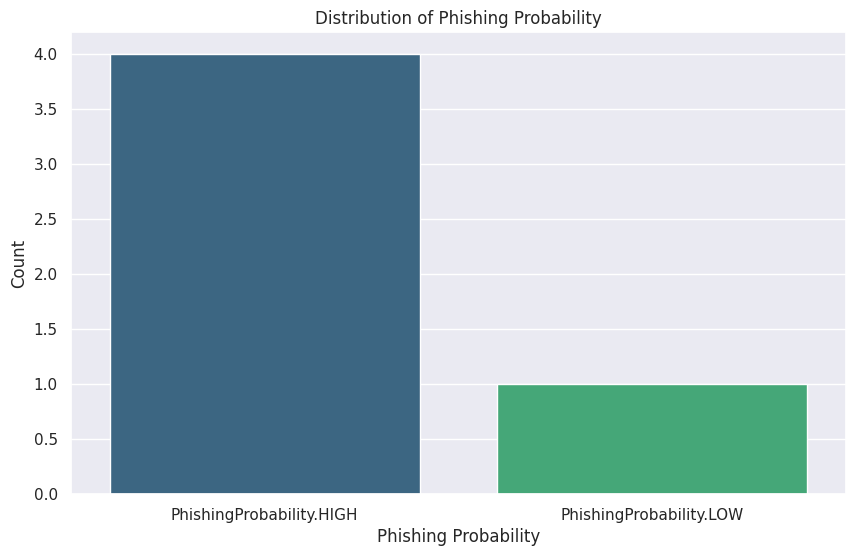

/tmp/ipykernel_21311/66192443.py:34: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_elements.values, y=top_elements.index, palette='mako')


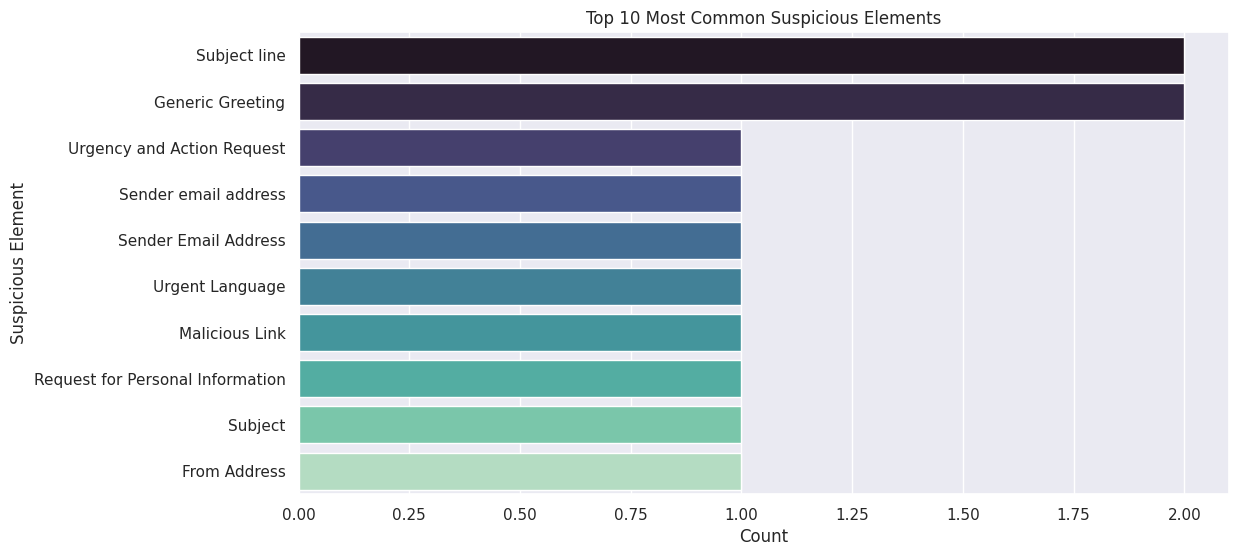

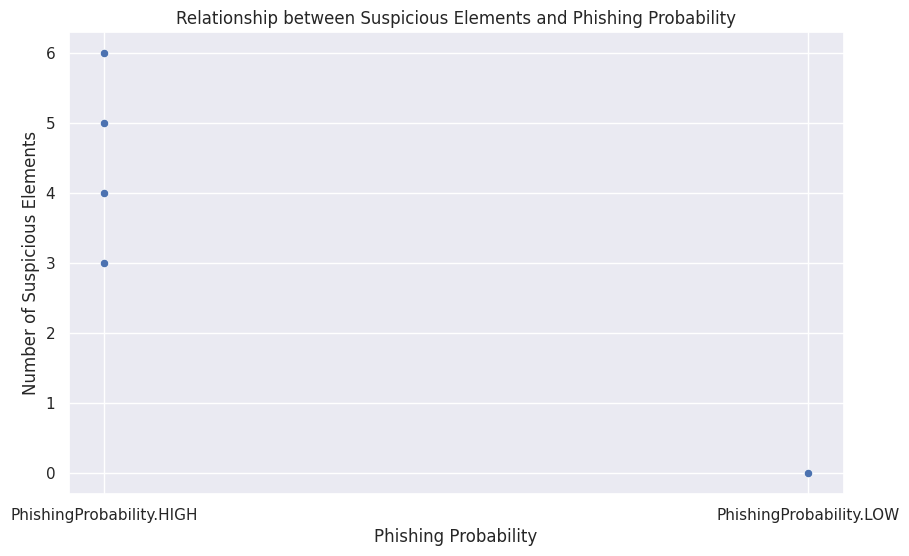

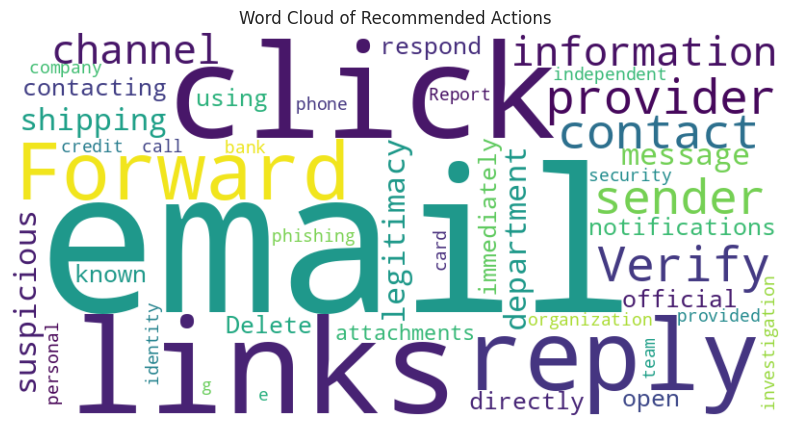


Detailed Information for High-Risk Emails:

Email 1:
Phishing Probability: PhishingProbability.HIGH
Suspicious Elements:
- Sender email address: The email address 'URHL52V4@F18SH5VY4DQ56Q4IP5QZF557TNJG' appears non-standard and lacks a recognizable FedEx domain.
- Subject line: The subject line uses a combination of French and English ('Re: phishing@pot, Veuillez confirmer vos informations d'exp��dition pour votre colis') which can be a tactic to mislead recipients.
- Urgency and Action Request: The email creates a sense of urgency by stating the package is 'en attente de livraison' and prompting the recipient to confirm shipping information.
Recommended Actions:
- Do not click on any links in the email.
- Do not reply to the email.
- Forward the email as a suspicious message to your IT department or email provider.
- Verify the legitimacy of any shipping notifications through official channels or by contacting the sender directly using known contact information.
Explanation: The emai

In [19]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from IPython.display import display, HTML
from wordcloud import WordCloud

# Set style for better-looking plots
sns.set_theme()

print("Creating summary of results...")
df_results = pd.DataFrame([result.model_dump() for result in results])

# Display summary statistics
print("\nSummary of Analysis Results:")
print(f"Total emails analyzed: {len(df_results)}")
print(f"Potential phishing emails: {df_results['is_potential_phishing'].sum()}")
print(f"Percentage of potential phishing emails: {df_results['is_potential_phishing'].mean()*100:.2f}%")

# Visualize phishing probability distribution
plt.figure(figsize=(10, 6))
sns.countplot(x='phishing_probability', data=df_results, hue='phishing_probability', legend=False, palette='viridis')
plt.title('Distribution of Phishing Probability')
plt.xlabel('Phishing Probability')
plt.ylabel('Count')
plt.show()

# Analyze and visualize suspicious elements
suspicious_elements = [element['element'] for sublist in df_results["suspicious_elements"] for element in sublist]
df_elements = pd.DataFrame({'element': suspicious_elements})

top_elements = df_elements["element"].value_counts().head(10)
plt.figure(figsize=(12, 6))
sns.barplot(x=top_elements.values, y=top_elements.index, palette='mako')
plt.title('Top 10 Most Common Suspicious Elements')
plt.xlabel('Count')
plt.ylabel('Suspicious Element')
plt.show()


# Correlation between suspicious elements and phishing probability
df_results['suspicious_element_count'] = df_results['suspicious_elements'].apply(len)

plt.figure(figsize=(10, 6))
sns.scatterplot(x='phishing_probability', y='suspicious_element_count', data=df_results)
plt.title('Relationship between Suspicious Elements and Phishing Probability')
plt.xlabel('Phishing Probability')
plt.ylabel('Number of Suspicious Elements')
plt.show()

# Word cloud of recommended actions
all_actions = ' '.join([' '.join(actions) for actions in df_results['recommended_actions']])
wordcloud = WordCloud(width=800, height=400, background_color='white').generate(all_actions)

plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('Word Cloud of Recommended Actions')
plt.show()

# Display detailed information for high-risk emails
high_risk_emails = df_results[df_results['phishing_probability'] == PhishingProbability.HIGH.value]
print("\nDetailed Information for High-Risk Emails:")
for idx, email in high_risk_emails.iterrows():
    print(f"\nEmail {idx+1}:")
    print(f"Phishing Probability: {email['phishing_probability']}")
    print("Suspicious Elements:")
    for element in email['suspicious_elements']:
        print(f"- {element['element']}: {element['reason']}")
    print("Recommended Actions:")
    for action in email['recommended_actions']:
        print(f"- {action}")
    print(f"Explanation: {email['explanation']}")
    print("-" * 50)

# Calculate and display overall risk score
risk_score_map = {PhishingProbability.LOW.value: 1, PhishingProbability.MEDIUM.value: 2, PhishingProbability.HIGH.value: 3}
df_results['risk_score'] = df_results['phishing_probability'].map(risk_score_map)
overall_risk_score = df_results['risk_score'].mean()

print(f"\nOverall Risk Score: {overall_risk_score:.2f} out of 3")

# Additional analysis
prob_counts = df_results['phishing_probability'].value_counts()
print("\nPhishing Probability Counts:")
print(prob_counts)

avg_suspicious = df_results['suspicious_element_count'].mean()
print(f"\nAverage number of suspicious elements per email: {avg_suspicious:.2f}")


all_actions = [action for actions in df_results['recommended_actions'] for action in actions]
action_counts = pd.Series(all_actions).value_counts()
print("\nTop 5 most common recommended actions:")
print(action_counts.head())

print("\nSample explanations:")
print(df_results['explanation'].sample(min(3, len(df_results))).to_string())

## Conclusion

This notebook demonstrates how to use LLMs for phishing email analysis. It covers setting up the environment, defining data models, implementing the analysis function, and creating a simple GUI for easy interaction. This approach can be extended and refined for more sophisticated email security applications.
